In [50]:
import pandas as pd
import numpy as np
from scipy.optimize import minimize_scalar
from scipy.stats import kendalltau, spearmanr, multivariate_normal, norm, chi2, kruskal, ranksums, bootstrap, permutation_test
from factor_analyzer.factor_analyzer import calculate_kmo, calculate_bartlett_sphericity
from factor_analyzer import FactorAnalyzer
from factor_analyzer.rotator import Rotator
from sklearn.decomposition import PCA
from itertools import combinations
from statsmodels.stats.correlation_tools import corr_nearest
import matplotlib.pyplot as plt
import warnings
from IPython.display import display
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
import pingouin as pg
import plotly.express as px
import plotly.graph_objects as go
import json
import subprocess
import tempfile
import os
from sklearn.svm import SVC

# Suppress minor convergence warnings during bootstrap iterations
warnings.filterwarnings("ignore")

In [ ]:
def evaluate_kmo_bartlett_factorability(
    df: pd.DataFrame = None,
    corr_matrix: pd.DataFrame = None,
    n_bootstraps: int = 1000,
    ci_level: float = 0.95,
    random_state: int = 42,
) -> dict:
    """Computes overall and per-item KMO and Bartlett's Test of Sphericity

    with regularized small-sample bootstrap confidence intervals.
    """
    rng = np.random.default_rng(random_state)

    if df is not None:
        clean_df = df.apply(pd.to_numeric, errors="coerce").dropna().astype(float)
        cols = list(clean_df.columns)
        n_obs, n_vars = clean_df.shape
        data_arr = clean_df.to_numpy()
        input_data = clean_df if corr_matrix is None else corr_matrix.copy()
        is_corr = corr_matrix is not None
    elif corr_matrix is not None:
        input_data = corr_matrix.copy()
        cols = list(corr_matrix.columns)
        n_obs = 27
        n_vars = len(cols)
        data_arr = None
        is_corr = True
    else:
        raise ValueError("Must provide either `df` or `corr_matrix`.")

    # 1. Ensure Positive Semi-Definiteness for Point Estimates
    if is_corr:
        evals = np.linalg.eigvalsh(input_data.values)
        if np.any(evals <= 1e-6):
            input_data = pd.DataFrame(
                corr_nearest(input_data.values, threshold=1e-6),
                index=cols,
                columns=cols,
            )

    # 2. Point Estimates
    kmo_per_item, kmo_total = calculate_kmo(input_data)
    chi_sq, p_val = calculate_bartlett_sphericity(input_data)

    # 3. Robust Small-Sample Bootstrapping with Regularization
    alpha_tail = (1.0 - ci_level) / 2.0
    low_pct = alpha_tail * 100.0
    high_pct = (1.0 - alpha_tail) * 100.0

    boot_kmo_tot = []
    boot_kmo_items = []
    boot_chis = []
    boot_pvals = []

    if data_arr is not None:
        for _ in range(n_bootstraps):
            # Resample rows with replacement
            idx = rng.choice(n_obs, size=n_obs, replace=True)
            sample = data_arr[idx, :].copy()

            # Guard against zero-variance columns in small sample
            stds = np.std(sample, axis=0)
            if np.any(stds == 0):
                zero_cols = np.where(stds == 0)[0]
                sample[:, zero_cols] += rng.normal(0, 1e-5, size=(n_obs, len(zero_cols)))

            # Compute empirical correlation matrix of resample
            r_boot = np.corrcoef(sample, rowvar=False)

            # Regularize if singular or non-positive definite
            evals_b = np.linalg.eigvalsh(r_boot)
            if np.any(evals_b <= 1e-6):
                r_boot = corr_nearest(r_boot, threshold=1e-6)

            try:
                items_b, tot_b = calculate_kmo(r_boot)
                chi_b, p_b = calculate_bartlett_sphericity(r_boot)

                if not np.isnan(tot_b) and not np.any(np.isnan(items_b)):
                    boot_kmo_tot.append(tot_b)
                    boot_kmo_items.append(items_b)
                    boot_chis.append(chi_b)
                    boot_pvals.append(p_b)
            except Exception:
                continue

        # Compute percentile confidence bounds
        if len(boot_kmo_tot) >= 20:
            kmo_tot_ci = (
                float(np.percentile(boot_kmo_tot, low_pct)),
                float(np.percentile(boot_kmo_tot, high_pct)),
            )
            chi_sq_ci = (
                float(np.percentile(boot_chis, low_pct)),
                float(np.percentile(boot_chis, high_pct)),
            )
            p_val_ci = (
                float(np.percentile(boot_pvals, low_pct)),
                float(np.percentile(boot_pvals, high_pct)),
            )

            boot_items_mat = np.array(boot_kmo_items)
            item_low = np.percentile(boot_items_mat, low_pct, axis=0)
            item_high = np.percentile(boot_items_mat, high_pct, axis=0)

            kmo_items_ci_df = pd.DataFrame(
                {
                    "KMO_Estimate": kmo_per_item,
                    "CI_Lower": item_low,
                    "CI_Upper": item_high,
                },
                index=cols,
            )
        else:
            kmo_tot_ci = (np.nan, np.nan)
            chi_sq_ci = (np.nan, np.nan)
            p_val_ci = (np.nan, np.nan)
            kmo_items_ci_df = pd.DataFrame(
                {
                    "KMO_Estimate": kmo_per_item,
                    "CI_Lower": np.nan,
                    "CI_Upper": np.nan,
                },
                index=cols,
            )
    else:
        kmo_tot_ci = (np.nan, np.nan)
        chi_sq_ci = (np.nan, np.nan)
        p_val_ci = (np.nan, np.nan)
        kmo_items_ci_df = pd.DataFrame(
            {
                "KMO_Estimate": kmo_per_item,
                "CI_Lower": np.nan,
                "CI_Upper": np.nan,
            },
            index=cols,
        )

    return {
        "kmo_total": float(kmo_total),
        "kmo_total_ci": kmo_tot_ci,
        "kmo_per_item": pd.Series(kmo_per_item, index=cols, name="KMO"),
        "kmo_per_item_cis": kmo_items_ci_df,
        "bartlett_chi_sq": float(chi_sq),
        "bartlett_chi_sq_ci": chi_sq_ci,
        "bartlett_p_val": float(p_val),
        "bartlett_p_val_ci": p_val_ci,
    }

In [ ]:
def _kendall_stat(x, y):
    return kendalltau(x, y, variant="b").statistic


def _spearman_stat(x, y):
    return spearmanr(x, y).statistic


def compute_ordinal_correlations(
    df: pd.DataFrame,
    n_bootstraps: int = 2000,
    confidence_level: float = 0.95,
    random_state: int = 42,
) -> dict:
    """Computes Kendall's tau-b and Spearman's rho correlation matrices, permutation

    p-values, and bootstrapped confidence intervals using scipy.stats.
    """
    cols = list(df.columns)
    n_cols = len(cols)
    rng = np.random.default_rng(random_state)

    # Initialize symmetric DataFrames
    results = {
        "kendall_tau": pd.DataFrame(np.eye(n_cols), index=cols, columns=cols),
        "kendall_pvalues": pd.DataFrame(
            np.zeros((n_cols, n_cols)), index=cols, columns=cols
        ),
        "kendall_ci_lower": pd.DataFrame(
            np.eye(n_cols), index=cols, columns=cols
        ),
        "kendall_ci_upper": pd.DataFrame(
            np.eye(n_cols), index=cols, columns=cols
        ),
        "spearman_rho": pd.DataFrame(np.eye(n_cols), index=cols, columns=cols),
        "spearman_pvalues": pd.DataFrame(
            np.zeros((n_cols, n_cols)), index=cols, columns=cols
        ),
        "spearman_ci_lower": pd.DataFrame(
            np.eye(n_cols), index=cols, columns=cols
        ),
        "spearman_ci_upper": pd.DataFrame(
            np.eye(n_cols), index=cols, columns=cols
        ),
    }

    for col_a_name, col_b_name in combinations(cols, 2):
        col_a = df[col_a_name].to_numpy(dtype=float)
        col_b = df[col_b_name].to_numpy(dtype=float)

        # 1. Point Estimates
        tau_val = _kendall_stat(col_a, col_b)
        rho_val = _spearman_stat(col_a, col_b)

        # 2. Permutation P-Values (Exact/Monte Carlo approach for small N)
        tau_perm = permutation_test(
            (col_a, col_b),
            statistic=_kendall_stat,
            permutation_type="pairings",
            n_resamples=n_bootstraps,
            random_state=rng,
        )
        rho_perm = permutation_test(
            (col_a, col_b),
            statistic=_spearman_stat,
            permutation_type="pairings",
            n_resamples=n_bootstraps,
            random_state=rng,
        )

        # 3. Standardized Bootstrap CIs (method='percentile' or 'BCa')
        tau_boot = bootstrap(
            (col_a, col_b),
            statistic=_kendall_stat,
            paired=True,
            confidence_level=confidence_level,
            n_resamples=n_bootstraps,
            method="percentile",
            random_state=rng,
        )
        rho_boot = bootstrap(
            (col_a, col_b),
            statistic=_spearman_stat,
            paired=True,
            confidence_level=confidence_level,
            n_resamples=n_bootstraps,
            method="percentile",
            random_state=rng,
        )

        # Fill matrices symmetrically
        for metric, val, pval, ci in [
            (
                "kendall",
                tau_val,
                tau_perm.pvalue,
                tau_boot.confidence_interval,
            ),
            ("spearman", rho_val, rho_perm.pvalue, rho_boot.confidence_interval),
        ]:
            prefix = "kendall_tau" if metric == "kendall" else "spearman_rho"
            p_prefix = f"{metric}_pvalues"
            low_prefix = f"{metric}_ci_lower"
            high_prefix = f"{metric}_ci_upper"

            for u, v in [(col_a_name, col_b_name), (col_b_name, col_a_name)]:
                results[prefix].loc[u, v] = float(val)
                results[p_prefix].loc[u, v] = float(pval)
                results[low_prefix].loc[u, v] = float(ci.low)
                results[high_prefix].loc[u, v] = float(ci.high)

    return results

In [ ]:
def _estimate_bivariate_polychoric(
    x: np.ndarray,
    y: np.ndarray,
    scale_categories: list[int] = None,
    smooth_zeros: bool = True,
) -> float:
    """Estimates the polychoric correlation between two ordinal series using

    Olsson's Two-Stage Maximum Likelihood Estimation (2S-MLE).
    """
    # 1. Zero-variance guard
    if np.std(x) == 0 or np.std(y) == 0:
        return 0.0

    # 2. Build contingency table
    if scale_categories is not None:
        cat_x = pd.Categorical(x, categories=scale_categories)
        cat_y = pd.Categorical(y, categories=scale_categories)
    else:
        cat_x = pd.Categorical(x, categories=np.sort(np.unique(x)))
        cat_y = pd.Categorical(y, categories=np.sort(np.unique(y)))

    freq_table = pd.crosstab(cat_x, cat_y, dropna=False).to_numpy(dtype=float)

    # 3. Small-sample Laplace smoothing for empty cells
    if smooth_zeros and np.any(freq_table == 0):
        freq_table = freq_table.copy()
        freq_table += 0.5

    n_total = np.sum(freq_table)
    if n_total == 0:
        return 0.0

    p_table = freq_table / n_total

    # 4. Latent marginal thresholds via inverse standard normal CDF
    p_x_cum = np.clip(np.cumsum(np.sum(p_table, axis=1))[:-1], 1e-6, 1.0 - 1e-6)
    p_y_cum = np.clip(np.cumsum(np.sum(p_table, axis=0))[:-1], 1e-6, 1.0 - 1e-6)

    tau_x = np.concatenate(([-np.inf], norm.ppf(p_x_cum), [np.inf]))
    tau_y = np.concatenate(([-np.inf], norm.ppf(p_y_cum), [np.inf]))

    r_dim, c_dim = freq_table.shape

    # 5. Bivariate Normal Negative Log-Likelihood
    def _neg_log_lik(rho: float) -> float:
        rho = np.clip(rho, -0.9999, 0.9999)
        cov = np.array([[1.0, rho], [rho, 1.0]])
        mvn = multivariate_normal(
            mean=[0.0, 0.0], cov=cov, allow_singular=True
        )

        log_lik = 0.0
        for r in range(r_dim):
            for c in range(c_dim):
                if freq_table[r, c] > 0:
                    # Joint probability inside the bin rectangle
                    p_cell = (
                        mvn.cdf([tau_x[r + 1], tau_y[c + 1]])
                        - mvn.cdf([tau_x[r], tau_y[c + 1]])
                        - mvn.cdf([tau_x[r + 1], tau_y[c]])
                        + mvn.cdf([tau_x[r], tau_y[c]])
                    )
                    log_lik += freq_table[r, c] * np.log(max(p_cell, 1e-12))
        return -log_lik

    # 6. Brent bounded scalar optimization
    res = minimize_scalar(
        _neg_log_lik, bounds=(-0.9999, 0.9999), method="bounded"
    )
    return float(res.x)

In [ ]:
def compute_polychoric_matrix(
    df: pd.DataFrame,
    scale_categories: list[int] = None,
    smooth_zeros: bool = True,
    ensure_positive_definite: bool = True,
) -> pd.DataFrame:
    """Computes a symmetric, positive-definite Polychoric Correlation Matrix

    using Olsson's 2S-MLE and statsmodels.
    """
    clean_df = df.apply(pd.to_numeric, errors="coerce").dropna().astype(float)
    cols = list(clean_df.columns)
    n_cols = len(cols)
    poly_matrix = pd.DataFrame(
        np.eye(n_cols), index=cols, columns=cols, dtype=float
    )

    # Compute pairwise combinations
    for (i, col_a), (j, col_b) in combinations(enumerate(cols), 2):
        x_vals = clean_df[col_a].to_numpy()
        y_vals = clean_df[col_b].to_numpy()

        rho = _estimate_bivariate_polychoric(
            x=x_vals,
            y=y_vals,
            scale_categories=scale_categories,
            smooth_zeros=smooth_zeros,
        )
        poly_matrix.iloc[i, j] = poly_matrix.iloc[j, i] = rho

    # Project to nearest positive definite matrix if eigenvalues <= 0
    if ensure_positive_definite:
        evals = np.linalg.eigvalsh(poly_matrix.values)
        if np.any(evals <= 1e-7):
            adjusted = corr_nearest(poly_matrix.values, threshold=1e-7)
            poly_matrix = pd.DataFrame(adjusted, index=cols, columns=cols)

    return poly_matrix

In [ ]:
def compute_pca_scree_analysis_fa(
    corr_matrix: pd.DataFrame,
    kaiser_cutoff: float = 1.0,
) -> dict:
    """Computes eigenvalues and Kaiser retention using factor_analyzer."""
    fa = FactorAnalyzer(
        n_factors=corr_matrix.shape[0], method="principal", is_corr_matrix=True
    )
    fa.fit(corr_matrix)

    ev, _ = fa.get_eigenvalues()
    pct_var, cum_var, _ = fa.get_factor_variance()

    n_kaiser = int(np.sum(ev >= kaiser_cutoff))

    summary_df = pd.DataFrame(
        {
            "Eigenvalue": ev,
            "% of Variance": pct_var * 100.0,
            "Cumulative %": cum_var * 100.0,
        },
        index=[f"Component {i + 1}" for i in range(len(ev))],
    )

    return {
        "eigenvalues": ev,
        "n_factors_kaiser": n_kaiser,
        "variance_table": summary_df,
        "total_variance_kaiser": (
            summary_df["Cumulative %"].iloc[n_kaiser - 1]
            if n_kaiser > 0
            else 0.0
        ),
    }

In [ ]:
def perform_horn_parallel_analysis(
    df: pd.DataFrame = None,
    corr_matrix: pd.DataFrame = None,
    n_observations: int = 27,
    n_simulations: int = 1000,
    percentile: float = 95.0,
    random_state: int = 42,
    plot_comparison: bool = True,
    save_path: str = None,
) -> dict:
    """Performs Horn's Parallel Analysis against Monte Carlo simulated uncorrelated noise."""
    rng = np.random.default_rng(random_state)

    if df is not None:
        clean_df = (
            df.apply(pd.to_numeric, errors="coerce").dropna().astype(float)
        )
        n_obs, n_vars = clean_df.shape
        emp_corr = (
            clean_df.corr().to_numpy()
            if corr_matrix is None
            else corr_matrix.to_numpy()
        )
    elif corr_matrix is not None:
        n_obs = n_observations
        n_vars = corr_matrix.shape[0]
        emp_corr = corr_matrix.to_numpy()
    else:
        raise ValueError("Must provide either `df` or `corr_matrix`.")

    # 1. Empirical Eigenvalues
    emp_eigenvalues = np.sort(np.linalg.eigvalsh(emp_corr))[::-1]

    # 2. Monte Carlo Simulation of Uncorrelated Gaussian Datasets (N x P)
    synthetic_evals = np.zeros((n_simulations, n_vars))
    for i in range(n_simulations):
        noise = rng.standard_normal(size=(n_obs, n_vars))
        noise_corr = np.corrcoef(noise, rowvar=False)
        synthetic_evals[i, :] = np.sort(np.linalg.eigvalsh(noise_corr))[::-1]

    simulated_mean = np.mean(synthetic_evals, axis=0)
    simulated_percentile = np.percentile(synthetic_evals, percentile, axis=0)

    # 3. Decision
    retained_mask = emp_eigenvalues > simulated_percentile
    n_factors_retained = int(np.sum(retained_mask))

    comparison_df = pd.DataFrame(
        {
            "Empirical Eigenvalue": emp_eigenvalues,
            f"Synthetic ({int(percentile)}th %ile)": simulated_percentile,
            "Synthetic (Mean)": simulated_mean,
            "Retain": ["Yes" if r else "No" for r in retained_mask],
        },
        index=[f"Component {i + 1}" for i in range(n_vars)],
    )

    if plot_comparison:
        plt.figure(figsize=(8, 5))
        comp_indices = np.arange(1, n_vars + 1)
        plt.plot(
            comp_indices,
            emp_eigenvalues,
            "o-",
            color="#1f77b4",
            linewidth=2,
            label="Empirical Eigenvalues",
        )
        plt.plot(
            comp_indices,
            simulated_percentile,
            "s--",
            color="#d62728",
            linewidth=1.75,
            label=f"Simulated {int(percentile)}th %ile",
        )
        plt.plot(
            comp_indices,
            simulated_mean,
            "^:",
            color="#7f7f7f",
            linewidth=1.25,
            label="Simulated Mean",
        )
        plt.axhline(
            y=1.0,
            color="black",
            linestyle=":",
            alpha=0.5,
            label=r"Kaiser ($\lambda = 1.0$)",
        )
        plt.title("Horn's Parallel Analysis vs. Scree Trace")
        plt.xlabel("Component Number")
        plt.ylabel("Eigenvalue")
        plt.xticks(comp_indices)
        plt.legend()
        plt.tight_layout()
        if save_path:
            plt.savefig(save_path, dpi=300)
        plt.show()

    return {
        "n_factors_parallel": n_factors_retained,
        "empirical_eigenvalues": emp_eigenvalues,
        "synthetic_percentile_eigenvalues": simulated_percentile,
        "synthetic_mean_eigenvalues": simulated_mean,
        "comparison_table": comparison_df,
    }

In [ ]:
def perform_abels_pca_oblimin(
    df: pd.DataFrame = None,
    corr_matrix: pd.DataFrame = None,
    n_factors: int = None,
    kaiser_cutoff: float = 1.0,
    rotation: str = "oblimin",
) -> dict:
    """Performs PCA on a correlation matrix or raw data with Direct Oblimin

    oblique rotation via factor_analyzer.Rotator.
    """
    if corr_matrix is not None:
        cols = list(corr_matrix.columns)
        r_mat = corr_matrix.to_numpy(dtype=float).copy()
    elif df is not None:
        clean_df = (
            df.apply(pd.to_numeric, errors="coerce").dropna().astype(float)
        )
        cols = list(clean_df.columns)
        r_mat = clean_df.corr().to_numpy(dtype=float)
    else:
        raise ValueError("Must provide either `df` or `corr_matrix`.")

    n_vars = len(cols)

    # 1. Ensure Positive Semi-Definiteness
    evals = np.linalg.eigvalsh(r_mat)
    if np.any(evals <= 1e-7):
        r_mat = corr_nearest(r_mat, threshold=1e-7)

    # 2. Eigendecomposition (Sorted Descending)
    evals, evecs = np.linalg.eigh(r_mat)
    sort_idx = np.argsort(evals)[::-1]
    sorted_evals = evals[sort_idx]
    sorted_evecs = evecs[:, sort_idx]

    # 3. Factor Retention Count
    if n_factors is None:
        n_factors = int(np.sum(sorted_evals >= kaiser_cutoff))
        n_factors = max(1, min(n_factors, n_vars))

    pct_variance = (sorted_evals / n_vars) * 100.0
    cum_pct_variance = np.cumsum(pct_variance)

    variance_summary = pd.DataFrame(
        {
            "Eigenvalue": sorted_evals,
            "% of Variance": pct_variance,
            "Cumulative %": cum_pct_variance,
        },
        index=[f"Component {i + 1}" for i in range(n_vars)],
    )

    # 4. Unrotated Principal Component Loadings: Lambda = V * sqrt(D)
    top_evals = sorted_evals[:n_factors]
    top_evecs = sorted_evecs[:, :n_factors]
    unrotated_loadings = top_evecs * np.sqrt(np.maximum(top_evals, 1e-12))

    comp_names = [f"Component {i + 1}" for i in range(n_factors)]

    # 5. Direct Oblimin Rotation via Rotator
    if n_factors > 1 and rotation is not None:
        rotator = Rotator(method=rotation)
        rotated_loadings = rotator.fit_transform(unrotated_loadings)
        phi_matrix = rotator.phi_
    else:
        rotated_loadings = unrotated_loadings
        phi_matrix = np.eye(n_factors)

    # Pattern Loadings Matrix (Table 3)
    pattern_loadings = pd.DataFrame(
        rotated_loadings, index=cols, columns=comp_names
    )

    # Structure Matrix (Table 4: Pattern * Phi)
    if phi_matrix is not None:
        structure_vals = np.dot(rotated_loadings, phi_matrix)
        structure_matrix = pd.DataFrame(
            structure_vals, index=cols, columns=comp_names
        )
        factor_correlations = pd.DataFrame(
            phi_matrix, index=comp_names, columns=comp_names
        )
    else:
        structure_matrix = pattern_loadings.copy()
        factor_correlations = pd.DataFrame(
            np.eye(n_factors), index=comp_names, columns=comp_names
        )

    # 6. Component Variable Clustering
    primary_assignments = pattern_loadings.abs().idxmax(axis=1)
    clustering = {comp: [] for comp in comp_names}
    for var_name, comp_assigned in primary_assignments.items():
        clustering[comp_assigned].append(var_name)

    return {
        "n_factors_retained": n_factors,
        "eigenvalues": sorted_evals,
        "variance_summary": variance_summary,
        "pattern_loadings": pattern_loadings,
        "structure_matrix": structure_matrix,
        "factor_correlations": factor_correlations,
        "component_assignments": clustering,
    }

In [ ]:
def _calc_alpha_from_corr(r: np.ndarray) -> float:
    """Computes standardized/ordinal alpha directly from a correlation matrix."""
    p = r.shape[0]
    if p <= 1:
        return np.nan
    sum_total = np.sum(r)
    trace_r = np.trace(r)
    if sum_total <= 0:
        return 0.0
    return float((p / (p - 1.0)) * (1.0 - (trace_r / sum_total)))


def _calc_omega_from_data_or_corr(
    data: np.ndarray, is_corr: bool = False
) -> tuple[float, np.ndarray, np.ndarray]:
    """Extracts McDonald's Omega (composite reliability) and 1-factor loadings

    using MINRES factor extraction on correlation matrix or raw data.
    """
    p = data.shape[0] if is_corr else data.shape[1]

    if is_corr:
        evals = np.linalg.eigvalsh(data)
        if np.any(evals <= 1e-6):
            data = corr_nearest(data, threshold=1e-6)

    # Use 'minres' which natively supports correlation matrices (unlike 'principal')
    fa = FactorAnalyzer(
        n_factors=1,
        method="minres",
        rotation=None,
        is_corr_matrix=is_corr,
    )
    
    try:
        fa.fit(data)
        loadings = np.clip(fa.loadings_.flatten(), -0.999, 0.999)
        uniquenesses = np.maximum(fa.get_uniquenesses(), 1e-4)
    except Exception:
        # Fallback to principal eigenvector if MINRES fails to converge
        evals, evecs = np.linalg.eigh(data if is_corr else np.corrcoef(data, rowvar=False))
        top_eval = max(evals[-1], 1e-12)
        top_evec = evecs[:, -1]
        loadings = np.clip(top_evec * np.sqrt(top_eval), -0.999, 0.999)
        uniquenesses = np.maximum(1.0 - loadings**2, 1e-4)

    # Orient loadings positively
    if np.sum(loadings) < 0:
        loadings = -loadings

    sum_l = np.sum(loadings)
    denom = (sum_l**2) + np.sum(uniquenesses)
    omega = float((sum_l**2) / denom) if denom > 0 else 0.0

    return omega, loadings, uniquenesses


def compute_ordinal_reliability(
    df: pd.DataFrame,
    poly_corr_matrix: pd.DataFrame = None,
    n_bootstraps: int = 1000,
    alpha_ci: float = 0.05,
    random_state: int = 42,
) -> dict:
    """Computes Ordinal Cronbach's Alpha, Standard Alpha, and McDonald's Omega

    with robust bootstrap confidence intervals.
    """
    clean_df = df.apply(pd.to_numeric, errors="coerce").dropna().astype(float)
    cols = list(clean_df.columns)
    data_arr = clean_df.to_numpy()
    n_obs = len(clean_df)
    conf_level = 1.0 - alpha_ci
    rng = np.random.default_rng(random_state)

    # 1. Standard Cronbach's Alpha (via Pingouin)
    std_alpha, std_alpha_ci = pg.cronbach_alpha(data=clean_df, ci=conf_level)

    # 2. Point Estimates for Ordinal Alpha and McDonald's Omega
    if poly_corr_matrix is not None:
        target_corr = poly_corr_matrix.to_numpy(dtype=float)
        ordinal_alpha = _calc_alpha_from_corr(target_corr)
        omega_val, lambda_loadings, unique_vars = _calc_omega_from_data_or_corr(
            target_corr, is_corr=True
        )
    else:
        target_corr = clean_df.corr().to_numpy()
        ordinal_alpha = _calc_alpha_from_corr(target_corr)
        omega_val, lambda_loadings, unique_vars = _calc_omega_from_data_or_corr(
            data_arr, is_corr=False
        )

    # 3. Small-Sample Bootstrapping for Ordinal Alpha & Omega CIs
    boot_ord_alphas = []
    boot_omegas = []

    for _ in range(n_bootstraps):
        idx = rng.choice(n_obs, size=n_obs, replace=True)
        sample = data_arr[idx, :].copy()

        # Guard against invariant columns
        stds = np.std(sample, axis=0)
        if np.any(stds == 0):
            zero_cols = np.where(stds == 0)[0]
            sample[:, zero_cols] += rng.normal(0, 1e-5, size=(n_obs, len(zero_cols)))

        r_boot = np.corrcoef(sample, rowvar=False)
        if np.any(np.isnan(r_boot)):
            continue

        b_ord = _calc_alpha_from_corr(r_boot)
        try:
            b_om, _, _ = _calc_omega_from_data_or_corr(r_boot, is_corr=True)
        except Exception:
            b_om = np.nan

        if not np.isnan(b_ord):
            boot_ord_alphas.append(b_ord)
        if not np.isnan(b_om):
            boot_omegas.append(b_om)

    # Percentile bounds
    low_pct = (alpha_ci / 2.0) * 100.0
    high_pct = (1.0 - alpha_ci / 2.0) * 100.0

    def _get_ci(arr):
        if len(arr) >= 20:
            return (float(np.percentile(arr, low_pct)), float(np.percentile(arr, high_pct)))
        return (np.nan, np.nan)

    loadings_summary = pd.DataFrame(
        {
            "Standardized_Loading (λ)": lambda_loadings,
            "Error_Variance (θ)": unique_vars,
        },
        index=cols,
    )

    return {
        "ordinal_cronbach_alpha": float(ordinal_alpha),
        "ordinal_alpha_ci_95": _get_ci(boot_ord_alphas),
        "composite_reliability_omega": float(omega_val),
        "omega_ci_95": _get_ci(boot_omegas),
        "standard_cronbach_alpha": float(std_alpha),
        "standard_alpha_ci_95": (float(std_alpha_ci[0]), float(std_alpha_ci[1])),
        "single_factor_loadings": loadings_summary,
    }

In [ ]:
def compare_metric_groups(
    df: pd.DataFrame,
    grouping_series: pd.Series,
    group_name: str = "Group",
    padjust_method: str = "bonf",
) -> dict:
    """Performs non-parametric group comparisons and post-hoc pairwise tests

    using pingouin and pandas.
    """
    metrics = list(df.columns)
    combined_df = df.copy()
    combined_df[group_name] = grouping_series.values
    combined_df = combined_df.dropna(subset=[group_name])

    unique_groups = combined_df[group_name].unique()
    k_groups = len(unique_groups)

    if k_groups < 2:
        raise ValueError(
            f"Need at least 2 distinct groups to compare, found: {unique_groups}"
        )

    # 1. Descriptive Statistics via Pandas Aggregation
    def _iqr(x):
        return x.quantile(0.75) - x.quantile(0.25)

    desc_df = (
        combined_df.groupby(group_name)[metrics]
        .agg(
            N="count",
            Median="median",
            IQR=_iqr,
            Mean="mean",
            SD=lambda x: x.std(ddof=1),
        )
        .stack(level=1)
        .reset_index()
        .rename(columns={"level_1": "Metric"})
        .sort_values(by=["Metric", group_name])
    )

    # 2. Statistical Tests (Mann-Whitney U or Kruskal-Wallis via Pingouin)
    test_rows = []
    pairwise_frames = []

    for metric in metrics:
        if k_groups == 2:
            g1_name, g2_name = unique_groups[0], unique_groups[1]
            g1_vals = combined_df[combined_df[group_name] == g1_name][
                metric
            ].dropna()
            g2_vals = combined_df[combined_df[group_name] == g2_name][
                metric
            ].dropna()

            mwu_res = pg.mwu(g1_vals, g2_vals, alternative="two-sided")
            pval = mwu_res["p-val"].iloc[0]
            # Pingouin gives Common Language Effect Size (cles) and rank-biserial (RBC)
            rbc = mwu_res["RBC"].iloc[0]

            test_rows.append(
                {
                    "Metric": metric,
                    "Test": "Mann-Whitney U",
                    "Statistic (U)": mwu_res["U-val"].iloc[0],
                    "p_value": pval,
                    "Effect_Size (RBC)": rbc,
                    "Significant (p < .05)": pval < 0.05,
                }
            )

        else:
            # Kruskal-Wallis test
            kw_res = pg.kruskal(
                data=combined_df, dv=metric, between=group_name
            )
            pval = kw_res["p-unc"].iloc[0]
            h_stat = kw_res["H"].iloc[0]
            n_total = len(combined_df[metric].dropna())

            # Epsilon-squared effect size
            eps_sq = (
                max(0.0, (h_stat - k_groups + 1) / (n_total - k_groups))
                if n_total > k_groups
                else np.nan
            )

            test_rows.append(
                {
                    "Metric": metric,
                    "Test": "Kruskal-Wallis",
                    "Statistic (H)": h_stat,
                    "p_value": pval,
                    "Effect_Size (eta_sq)": eps_sq,
                    "Significant (p < .05)": pval < 0.05,
                }
            )

            # Post-hoc Pairwise Tests with Correction
            pw_res = pg.pairwise_tests(
                data=combined_df,
                dv=metric,
                between=group_name,
                parametric=False,
                padjust=padjust_method,
            )
            pw_res["Metric"] = metric
            pairwise_frames.append(pw_res)

    test_df = pd.DataFrame(test_rows)
    pairwise_df = pd.concat(pairwise_frames, ignore_index=True) if pairwise_frames else None

    return {
        "descriptive_stats": desc_df,
        "overall_tests": test_df,
        "pairwise_comparisons": pairwise_df,
    }


def compute_metric_distribution_summary(
    df: pd.DataFrame,
    scale_values: list = [0, 1, 2],
    include_parametric: bool = True,
) -> pd.DataFrame:
    """Computes frequency distributions, proportions, medians, IQRs, and

    parametric descriptives using vectorized pandas operations.
    """
    # 1. Ensure discrete categorical scale across all columns
    cat_df = df.apply(lambda col: pd.Categorical(col, categories=scale_values))

    # 2. Vectorized Counts and Percentages
    counts_df = (
        cat_df.apply(lambda col: col.value_counts(dropna=True))
        .T.add_prefix("Count_")
    )
    n_valid = df.notna().sum()
    pcts_df = (
        counts_df.div(n_valid, axis=0) * 100.0
    ).round(1).rename(columns=lambda c: c.replace("Count_", "Pct_"))

    # 3. Interleaved Frequency Columns: Count_0, Pct_0, Count_1, Pct_1, ...
    freq_cols = []
    for val in scale_values:
        freq_cols.extend([f"Count_{val}", f"Pct_{val}"])
    freq_summary = pd.concat([counts_df, pcts_df], axis=1)[freq_cols]

    # 4. Ordinal / Non-parametric Aggregations
    q25 = df.quantile(0.25)
    q75 = df.quantile(0.75)
    ord_stats = pd.DataFrame(
        {
            "N": n_valid,
            "Median": df.median(),
            "Q1 (25%)": q25,
            "Q3 (75%)": q75,
            "IQR": q75 - q25,
        },
        index=df.columns,
    )

    # 5. Assemble Summary Table
    summary_df = pd.concat([ord_stats[["N"]], freq_summary, ord_stats.drop(columns=["N"])], axis=1)

    # 6. Optional Parametric Descriptives
    if include_parametric:
        summary_df["Mean"] = df.mean().round(2)
        summary_df["SD"] = df.std(ddof=1).round(2)

    summary_df.index.name = "Metric"
    return summary_df

In [48]:
def _compute_gap_statistic(
    data: np.ndarray,
    k_range: list[int],
    n_bootstraps: int = 500,
    random_state: int = 42,
) -> tuple[dict, dict, dict, int]:
    """Computes WSS (Inertia) and Tibshirani's Gap Statistic with 1-SE rule."""
    rng = np.random.default_rng(random_state)
    n_samples, n_features = data.shape

    feat_min, feat_max = data.min(axis=0), data.max(axis=0)

    inertias = {}
    gap_stats = {}
    gap_std_errs = {}

    def _get_inertia(x, k, seed):
        km = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(x)
        return km.inertia_

    for k in k_range:
        orig_inertia = _get_inertia(data, k, random_state)
        inertias[k] = float(orig_inertia)
        log_orig = np.log(max(orig_inertia, 1e-12))

        null_log_inertias = []
        for _ in range(n_bootstraps):
            null_data = rng.uniform(feat_min, feat_max, size=(n_samples, n_features))
            null_inertia = _get_inertia(null_data, k, seed=None)
            null_log_inertias.append(np.log(max(null_inertia, 1e-12)))

        mean_null_log = np.mean(null_log_inertias)
        sd_k = np.std(null_log_inertias, ddof=1)
        gap_stats[k] = float(mean_null_log - log_orig)
        gap_std_errs[k] = float(sd_k * np.sqrt(1.0 + 1.0 / n_bootstraps))

    # 1-SE optimal rule: smallest k where Gap(k) >= Gap(k+1) - SE(k+1)
    k_list = sorted(gap_stats.keys())
    optimal_k = k_list[0]
    for i in range(len(k_list) - 1):
        curr_k, next_k = k_list[i], k_list[i + 1]
        if gap_stats[curr_k] >= (gap_stats[next_k] - gap_std_errs[next_k]):
            optimal_k = curr_k
            break
    else:
        optimal_k = max(gap_stats, key=gap_stats.get)

    return inertias, gap_stats, gap_std_errs, optimal_k


def compute_pre_clustering_triangulation(
    df_metrics: pd.DataFrame = None,
    poly_corr_matrix: pd.DataFrame = None,
    k_range: range = range(2, 6),
    n_bootstraps_gap: int = 500,
    random_state: int = 42,
    plot_results: bool = True,
    save_path: str = None,
) -> dict:
    """Performs pre-clustering triangulation across variables/metrics using:

    1. Elbow Method (Inertia / WCSS)
    2. Silhouette analysis
    3. Gap Statistic (1-SE Rule)
    4. Ward's Hierarchical Dendrogram
    """
    if poly_corr_matrix is not None:
        corr_df = poly_corr_matrix.copy()
    elif df_metrics is not None:
        corr_df = df_metrics.corr()
    else:
        raise ValueError("Must provide either `df_metrics` or `poly_corr_matrix`.")

    metric_names = list(corr_df.columns)
    p_vars = len(metric_names)

    # Strictly cap k below the variable count
    valid_k_list = [k for k in k_range if k < p_vars]
    if not valid_k_list:
        raise ValueError(f"k_range values must be strictly less than number of metrics ({p_vars}).")

    # 1. Angular correlation distance: D = sqrt(2 * (1 - R))
    r_clipped = np.clip(corr_df.values, -1.0, 1.0)
    dist_matrix = np.sqrt(np.maximum(2.0 * (1.0 - r_clipped), 0.0))
    np.fill_diagonal(dist_matrix, 0.0)
    condensed_dist = squareform(dist_matrix, checks=False)

    # 2. Elbow Method (Compute WSS from k=1 to max(k))
    elbow_k_list = list(range(1, max(valid_k_list) + 1))
    wss_scores = {}
    for k in elbow_k_list:
        km = KMeans(n_clusters=k, random_state=random_state, n_init=10).fit(dist_matrix)
        wss_scores[k] = float(km.inertia_)

    # Detect elbow point via distance to chord line
    x_pts = np.array(elbow_k_list)
    y_pts = np.array([wss_scores[k] for k in elbow_k_list])
    if len(x_pts) > 2:
        line_vec = np.array([x_pts[-1] - x_pts[0], y_pts[-1] - y_pts[0]])
        line_vec_norm = line_vec / np.sqrt(np.sum(line_vec**2))
        vec_from_first = np.column_stack([x_pts - x_pts[0], y_pts - y_pts[0]])
        parallel_proj = np.outer(np.dot(vec_from_first, line_vec_norm), line_vec_norm)
        dist_to_chord = np.linalg.norm(vec_from_first - parallel_proj, axis=1)
        optimal_k_elbow = int(x_pts[np.argmax(dist_to_chord)])
    else:
        optimal_k_elbow = valid_k_list[0]

    # 3. Silhouette Analysis (scikit-learn)
    silhouette_scores = {}
    for k in valid_k_list:
        labels = AgglomerativeClustering(
            n_clusters=k, metric="precomputed", linkage="average"
        ).fit_predict(dist_matrix)
        silhouette_scores[k] = float(
            silhouette_score(dist_matrix, labels, metric="precomputed")
        )

    optimal_k_silhouette = max(silhouette_scores, key=silhouette_scores.get)

    # 4. Gap Statistic (scikit-learn KMeans engine)
    _, gap_stats, gap_std_errs, optimal_k_gap = _compute_gap_statistic(
        data=dist_matrix,
        k_range=valid_k_list,
        n_bootstraps=n_bootstraps_gap,
        random_state=random_state,
    )

    # 5. Ward's Hierarchical Linkage (scipy)
    ward_linkage_matrix = linkage(condensed_dist, method="ward")

    # 6. Triangulation Summary Table
    triangulation_table = pd.DataFrame(
        {
            "Inertia (Elbow WCSS)": [wss_scores.get(k, np.nan) for k in valid_k_list],
            "Silhouette Score": [silhouette_scores.get(k, np.nan) for k in valid_k_list],
            "Gap Statistic": [gap_stats.get(k, np.nan) for k in valid_k_list],
            "Gap Std Error": [gap_std_errs.get(k, np.nan) for k in valid_k_list],
        },
        index=[f"k = {k}" for k in valid_k_list],
    )

    # 7. Visual Dashboard (4 Distinct Subgraphs)
    if plot_results:
        fig, axes = plt.subplots(1, 4, figsize=(24, 5))

        # Subgraph 1: Elbow Method (Inertia)
        axes[0].plot(
            elbow_k_list,
            [wss_scores[k] for k in elbow_k_list],
            "o-",
            color="#8c564b",
            linewidth=2,
            markersize=7,
        )
        axes[0].axvline(
            optimal_k_elbow,
            color="firebrick",
            linestyle="--",
            label=f"Elbow Knee (k={optimal_k_elbow})",
        )
        axes[0].set_title("Elbow Method (WCSS)", fontsize=12, pad=10)
        axes[0].set_xlabel("Number of Clusters (k)")
        axes[0].set_ylabel("Inertia (WCSS)")
        axes[0].set_xticks(elbow_k_list)
        axes[0].grid(axis="both", linestyle=":", alpha=0.6)
        axes[0].legend()

        # Subgraph 2: Silhouette Curve
        axes[1].plot(
            valid_k_list,
            [silhouette_scores[k] for k in valid_k_list],
            "o-",
            color="#1f77b4",
            linewidth=2,
            markersize=7,
        )
        axes[1].axvline(
            optimal_k_silhouette,
            color="firebrick",
            linestyle="--",
            label=f"Max Silhouette (k={optimal_k_silhouette})",
        )
        axes[1].set_title("Silhouette Analysis", fontsize=12, pad=10)
        axes[1].set_xlabel("Number of Clusters (k)")
        axes[1].set_ylabel("Average Silhouette Width")
        axes[1].set_xticks(valid_k_list)
        axes[1].grid(axis="both", linestyle=":", alpha=0.6)
        axes[1].legend()

        # Subgraph 3: Gap Statistic Curve
        axes[2].errorbar(
            valid_k_list,
            [gap_stats[k] for k in valid_k_list],
            yerr=[gap_std_errs[k] for k in valid_k_list],
            fmt="s-",
            color="#2ca02c",
            ecolor="#2ca02c",
            capsize=4,
            linewidth=2,
            markersize=6,
        )
        axes[2].axvline(
            optimal_k_gap,
            color="firebrick",
            linestyle="--",
            label=f"Optimal Gap (k={optimal_k_gap})",
        )
        axes[2].set_title(f"Gap Statistic ($B={n_bootstraps_gap}$)", fontsize=12, pad=10)
        axes[2].set_xlabel("Number of Clusters (k)")
        axes[2].set_ylabel("Gap Statistic $Gap(k)$")
        axes[2].set_xticks(valid_k_list)
        axes[2].grid(axis="both", linestyle=":", alpha=0.6)
        axes[2].legend()

        # Subgraph 4: Ward's Dendrogram
        dendrogram(
            ward_linkage_matrix,
            labels=metric_names,
            orientation="right",
            ax=axes[3],
            leaf_font_size=9,
        )
        axes[3].set_title("Ward Hierarchical Dendrogram", fontsize=12, pad=10)
        axes[3].set_xlabel("Ward Dissimilarity Distance")

        plt.tight_layout()
        if save_path:
            plt.savefig(save_path, dpi=300)
        plt.show()

    return {
        "triangulation_table": triangulation_table,
        "wss_scores": wss_scores,
        "optimal_k_elbow": optimal_k_elbow,
        "optimal_k_silhouette": optimal_k_silhouette,
        "optimal_k_gap": optimal_k_gap,
        "ward_linkage": ward_linkage_matrix,
        "distance_matrix": pd.DataFrame(
            dist_matrix, index=metric_names, columns=metric_names
        ),
    }

In [46]:
def run_nbclust_via_rscript(
    data: pd.DataFrame | np.ndarray,
    min_nc: int = 2,
    max_nc: int = 6,
    method: str = "kmeans",
    distance: str = "euclidean",
    index: str = "alllong",
) -> dict:
    """Executes NbClust via Rscript with robust voting extraction and Inf filtering."""
    if not isinstance(data, pd.DataFrame):
        df_input = pd.DataFrame(data)
    else:
        df_input = data.copy()

    n_samples, _ = df_input.shape
    safe_max_nc = min(max_nc, max(2, n_samples // 4))

    with (
        tempfile.NamedTemporaryFile(
            mode="w", suffix=".csv", delete=False
        ) as tmp_in,
        tempfile.NamedTemporaryFile(
            mode="w", suffix="_bestnc.csv", delete=False
        ) as tmp_bestnc,
        tempfile.NamedTemporaryFile(
            mode="w", suffix="_allidx.csv", delete=False
        ) as tmp_allidx,
        tempfile.NamedTemporaryFile(
            mode="w", suffix="_part.csv", delete=False
        ) as tmp_part,
    ):
        in_path = tmp_in.name
        bestnc_path = tmp_bestnc.name
        allidx_path = tmp_allidx.name
        part_path = tmp_part.name

    try:
        df_input.to_csv(in_path, index=False)

        r_script = f"""
        suppressPackageStartupMessages(library(NbClust))

        df <- read.csv("{in_path}", check.names=FALSE)
        
        res <- tryCatch({{
            NbClust(
                data = df, 
                min.nc = {min_nc}, 
                max.nc = {safe_max_nc}, 
                method = "{method}", 
                distance = "{distance}", 
                index = "{index}"
            )
        }}, error = function(e) {{
            NbClust(
                data = df, 
                min.nc = {min_nc}, 
                max.nc = {safe_max_nc}, 
                method = "{method}", 
                distance = "{distance}", 
                index = "alllong"
            )
        }})

        write.csv(as.data.frame(res$Best.nc), file="{bestnc_path}", row.names=TRUE)
        write.csv(as.data.frame(res$All.index), file="{allidx_path}", row.names=TRUE)
        write.csv(data.frame(Partition=as.numeric(res$Best.partition)), file="{part_path}", row.names=FALSE)
        """

        proc = subprocess.run(
            ["Rscript", "-e", r_script], capture_output=True, text=True
        )

        if proc.returncode != 0:
            raise RuntimeError(f"R script execution failed:\n{proc.stderr}")

        best_nc_df = pd.read_csv(bestnc_path, index_col=0)
        all_indices_df = pd.read_csv(allidx_path, index_col=0)
        best_partition = (
            pd.read_csv(part_path)["Partition"].to_numpy(dtype=int)
        )

        # Extract only finite, valid integer cluster counts (min_nc <= k <= max_nc)
        raw_votes = pd.to_numeric(best_nc_df.iloc[0], errors="coerce").dropna()
        valid_votes = raw_votes[
            np.isfinite(raw_votes) & (raw_votes >= min_nc) & (raw_votes <= max_nc)
        ].astype(int)

        votes_tally = valid_votes.value_counts().sort_index()
        optimal_k = int(votes_tally.idxmax()) if not votes_tally.empty else min_nc

        return {
            "optimal_k": optimal_k,
            "votes_per_k": {int(k): int(v) for k, v in votes_tally.items()},
            "best_nc_summary": best_nc_df,
            "all_indices_table": all_indices_df,
            "best_partition": best_partition,
        }

    finally:
        for p in [in_path, bestnc_path, allidx_path, part_path]:
            if os.path.exists(p):
                os.remove(p)

In [53]:
def _add_svm_hyperplanes_3d(
    fig: go.Figure,
    X: np.ndarray,
    labels: np.ndarray,
    cluster_tags: list[str],
    palette: list[str],
) -> None:
    """Fits linear SVMs and renders translucent separating hyperplanes in 3D."""
    unique_clusters = np.unique(labels)
    n_classes = len(unique_clusters)
    if n_classes < 2:
        return

    # Spatial bounding box with slight padding
    x_min, x_max = X[:, 0].min() - 0.3, X[:, 0].max() + 0.3
    y_min, y_max = X[:, 1].min() - 0.3, X[:, 1].max() + 0.3
    grid_x, grid_y = np.meshgrid(
        np.linspace(x_min, x_max, 25), np.linspace(y_min, y_max, 25)
    )

    # Multi-class One-vs-Rest or Binary SVM
    svm = SVC(kernel="linear", C=1.0, decision_function_shape="ovr")
    svm.fit(X[:, :3], labels)

    coefs = svm.coef_  # Shape: (n_planes, 3)
    intercepts = svm.intercept_  # Shape: (n_planes,)

    for idx in range(len(intercepts)):
        w = coefs[idx]
        b = intercepts[idx]

        # Hyperplane equation: w0*x + w1*y + w2*z + b = 0  =>  z = (-w0*x - w1*y - b) / w2
        if np.abs(w[2]) > 1e-4:
            grid_z = (-w[0] * grid_x - w[1] * grid_y - b) / w[2]

            # Clip grid_z to reasonable data bounds to avoid visual overflow
            z_min_lim, z_max_lim = X[:, 2].min() - 1.0, X[:, 2].max() + 1.0
            grid_z = np.clip(grid_z, z_min_lim, z_max_lim)

            color = palette[idx % len(palette)]
            name = (
                f"Hyperplane (Cl.{idx+1} vs Rest)"
                if n_classes > 2
                else "SVM Separating Hyperplane"
            )

            fig.add_trace(
                go.Surface(
                    x=grid_x,
                    y=grid_y,
                    z=grid_z,
                    opacity=0.22,
                    showscale=False,
                    colorscale=[[0, color], [1, color]],
                    name=name,
                    showlegend=True,
                    hoverinfo="skip",
                )
            )


def _add_svm_hyperplanes_2d(
    fig: go.Figure,
    X: np.ndarray,
    labels: np.ndarray,
    palette: list[str],
) -> None:
    """Fits linear SVM and renders 2D decision boundary lines."""
    unique_clusters = np.unique(labels)
    n_classes = len(unique_clusters)
    if n_classes < 2:
        return

    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    x_vals = np.linspace(x_min, x_max, 100)

    svm = SVC(kernel="linear", C=1.0, decision_function_shape="ovr")
    svm.fit(X[:, :2], labels)

    coefs = svm.coef_
    intercepts = svm.intercept_

    for idx in range(len(intercepts)):
        w = coefs[idx]
        b = intercepts[idx]

        # 2D Line equation: w0*x + w1*y + b = 0 => y = (-w0*x - b) / w1
        if np.abs(w[1]) > 1e-4:
            y_vals = (-w[0] * x_vals - b) / w[1]
            color = palette[idx % len(palette)]
            name = (
                f"Boundary (Cl.{idx+1} vs Rest)"
                if n_classes > 2
                else "SVM Decision Boundary"
            )

            fig.add_trace(
                go.Scatter(
                    x=x_vals,
                    y=y_vals,
                    mode="lines",
                    line=dict(color=color, dash="dash", width=1.5),
                    name=name,
                    hoverinfo="skip",
                )
            )


def project_and_cluster_publications(
    df_metrics: pd.DataFrame,
    pca_results: dict,
    n_clusters: int,
    clustering_method: str = "kmeans",
    publication_labels: list[str] = None,
    draw_hyperplanes: bool = True,
    random_state: int = 42,
    plot_scatter: bool = True,
    save_path: str = None,
) -> dict:
    """Standardizes metrics, projects publications onto PCA axes via least-squares,

    clusters them, and renders an interactive 3D/2D Plotly graph with optional SVM hyperplanes.
    """
    n_obs, _ = df_metrics.shape
    pub_ids = (
        list(publication_labels)
        if publication_labels is not None
        else [f"Pub_{i+1:02d}" for i in range(n_obs)]
    )

    # 1. Preprocessing Pipeline: Impute -> Standardize
    preprocessor = make_pipeline(
        SimpleImputer(strategy="most_frequent"), StandardScaler()
    )
    z_scores = preprocessor.fit_transform(
        df_metrics.apply(pd.to_numeric, errors="coerce")
    )

    # 2. Project Component Scores via Least-Squares (Z = Scores @ Loadings.T)
    pattern_loadings = np.nan_to_num(
        pca_results["pattern_loadings"].to_numpy(dtype=float), nan=0.0
    )
    n_components = pattern_loadings.shape[1]
    comp_names = [f"PCA_Comp_{i+1}" for i in range(n_components)]

    projected_scores, _, _, _ = np.linalg.lstsq(
        pattern_loadings, z_scores.T, rcond=None
    )
    projected_scores = projected_scores.T  # Shape: (N, n_components)

    df_scores = pd.DataFrame(
        projected_scores, index=pub_ids, columns=comp_names
    )

    # 3. Clustering Execution
    if clustering_method.lower() == "kmeans":
        cluster_model = KMeans(
            n_clusters=n_clusters, random_state=random_state, n_init=20
        )
    elif clustering_method.lower() == "hierarchical":
        cluster_model = AgglomerativeClustering(
            n_clusters=n_clusters, linkage="ward"
        )
    else:
        raise ValueError(
            "clustering_method must be either 'kmeans' or 'hierarchical'"
        )

    cluster_labels = cluster_model.fit_predict(projected_scores)
    cluster_tags = [f"Cluster_{c+1}" for c in cluster_labels]

    # 4. Aggregated Summaries
    df_clustered = df_scores.copy()
    df_clustered.insert(0, "Assigned_Cluster", cluster_tags)
    df_clustered.insert(0, "Publication", pub_ids)

    cluster_centroids = df_scores.groupby(cluster_tags).mean().sort_index()

    df_original = df_metrics.copy()
    df_original.index = pub_ids
    df_original["Assigned_Cluster"] = cluster_tags
    metric_profiles = df_original.groupby("Assigned_Cluster").mean(
        numeric_only=True
    ).sort_index()

    # 5. Interactive 3D / 2D Plotly Visualization
    fig = None
    palette = px.colors.qualitative.Plotly

    if plot_scatter and n_components >= 2:
        plot_df = df_clustered.copy()

        if n_components >= 3:
            # Interactive 3D Scatter Plot
            fig = px.scatter_3d(
                plot_df,
                x=comp_names[0],
                y=comp_names[1],
                z=comp_names[2],
                color="Assigned_Cluster",
                text="Publication",
                title=f"3D Publication Clusters & SVM Hyperplanes (k={n_clusters})",
                hover_data={"Publication": True, "Assigned_Cluster": True},
                color_discrete_sequence=palette,
            )

            fig.update_traces(
                marker=dict(
                    size=6,
                    line=dict(width=1, color="DarkSlateGrey"),
                    opacity=0.9,
                ),
                textposition="top center",
                textfont=dict(size=10),
            )

            # Draw SVM 3D Hyperplanes
            if draw_hyperplanes:
                _add_svm_hyperplanes_3d(
                    fig=fig,
                    X=projected_scores,
                    labels=cluster_labels,
                    cluster_tags=cluster_tags,
                    palette=palette,
                )

            fig.update_layout(
                margin=dict(l=0, r=0, b=0, t=40),
                scene=dict(
                    xaxis_title=comp_names[0],
                    yaxis_title=comp_names[1],
                    zaxis_title=comp_names[2],
                ),
                legend=dict(
                    title="Legend",
                    yanchor="top",
                    y=0.95,
                    xanchor="left",
                    x=0.02,
                ),
            )

        else:
            # Interactive 2D Scatter Plot
            fig = px.scatter(
                plot_df,
                x=comp_names[0],
                y=comp_names[1],
                color="Assigned_Cluster",
                text="Publication",
                title=f"2D Publication Clusters & SVM Decision Boundaries (k={n_clusters})",
                hover_data={"Publication": True, "Assigned_Cluster": True},
                color_discrete_sequence=palette,
            )
            fig.update_traces(
                marker=dict(size=10, line=dict(width=1, color="black")),
                textposition="top right",
                textfont=dict(size=10),
            )

            # Draw SVM 2D Boundary Lines
            if draw_hyperplanes:
                _add_svm_hyperplanes_2d(
                    fig=fig,
                    X=projected_scores,
                    labels=cluster_labels,
                    palette=palette,
                )

            fig.update_layout(
                xaxis_title=comp_names[0],
                yaxis_title=comp_names[1],
            )

        fig.show()

        if save_path:
            if save_path.endswith(".html"):
                fig.write_html(save_path)
            else:
                fig.write_image(save_path)

    return {
        "projected_scores": df_scores,
        "clustered_publications": df_clustered,
        "cluster_centroids": cluster_centroids,
        "cluster_metric_profiles": metric_profiles,
        "figure": fig,
    }

In [29]:
# --- Execution Parameters ---
excel_path = "/home/david/Git/SDLT_Number_Crunching/Data/adiya_isla_scores.xlsx"
consensus_sheet_name = "Whole"
n_bootstraps = 1000
random_state = 42

pipeline_results = {}

# =========================================================================
# STEP 1: Load and Clean Dataset
# =========================================================================
xls = pd.ExcelFile(excel_path)
df_consensus = pd.read_excel(xls, sheet_name=consensus_sheet_name)

# Extract publication identifiers for downstream clustering labels
pub_labels = df_consensus["Publication"].astype(str).tolist() if "Publication" in df_consensus.columns else None

# Filter and clean numerical rating columns (drop metadata columns like 'Publication')
if "Publication" in df_consensus.columns:
    df_metrics = df_consensus.drop(columns=["Publication"])
else:
    df_metrics = df_consensus.copy()

# Ensure purely numeric float type
df_metrics = df_metrics.apply(pd.to_numeric, errors="coerce").astype(float)
pipeline_results["consensus_data"] = df_metrics



In [30]:

# =========================================================================
# STEP 2: Ordinal Correlation Matrices (Polychoric, Kendall, Spearman)
# =========================================================================
print("\n" + "=" * 70)
print("STEP 2: COMPUTING ORDINAL & POLYCHORIC CORRELATIONS")
print("=" * 70)

# Polychoric Matrix (projected to nearest positive definite)
poly_corr = compute_polychoric_matrix(
    df=df_metrics,
    ensure_positive_definite=True,
)
pipeline_results["polychoric_matrix"] = poly_corr

# Non-parametric Kendall's tau-b and Spearman's rho with permutation p-values and bootstrap CIs
rank_corrs = compute_ordinal_correlations(
    df=df_metrics,
    n_bootstraps=n_bootstraps,
    random_state=random_state,
)
pipeline_results["ordinal_correlations"] = rank_corrs

print("Polychoric Correlation Matrix (Nearest Positive Definite):")
display(poly_corr.round(3))

# Abels et al. screening: check if any metric fails to correlate (all |r| < 0.30)
off_diag = poly_corr.values.copy()
np.fill_diagonal(off_diag, 0.0)
max_corr_per_item = pd.Series(np.max(np.abs(off_diag), axis=1), index=df_metrics.columns)
low_corr_items = max_corr_per_item[max_corr_per_item < 0.30].index.tolist()

if low_corr_items:
    print(f"\n[Warning] Items with max polychoric correlation < 0.30: {low_corr_items}")
else:
    print("\nAll items meet the minimum correlation threshold (max |r| >= 0.30).")



STEP 2: COMPUTING ORDINAL & POLYCHORIC CORRELATIONS
Polychoric Correlation Matrix (Nearest Positive Definite):


,Chain of Custody,Authenticity,Integrity,Reliability,Lawful Acquisition,Fact vs Inference,Competence and Qualification,Repeatability and reproducibility,Privacy compliance
Chain of Custody,1.000,0.739,0.664,-0.132,0.130,-0.318,-0.061,-0.218,0.623
Authenticity,0.739,1.000,0.817,0.020,0.250,-0.119,0.042,-0.218,0.755
Integrity,0.664,0.817,1.000,0.316,0.153,-0.104,-0.047,0.164,0.559
Reliability,-0.132,0.020,0.316,1.000,0.179,0.287,0.204,0.463,0.101
Lawful Acquisition,0.130,0.250,0.153,0.179,1.000,0.319,0.402,-0.014,0.584
Fact vs Inference,-0.318,-0.119,-0.104,0.287,0.319,1.000,0.473,0.372,-0.248
Competence and Qualification,-0.061,0.042,-0.047,0.204,0.402,0.473,1.000,0.493,0.246
Repeatability and reproducibility,-0.218,-0.218,0.164,0.463,-0.014,0.372,0.493,1.000,-0.166
Privacy compliance,0.623,0.755,0.559,0.101,0.584,-0.248,0.246,-0.166,1.000



All items meet the minimum correlation threshold (max |r| >= 0.30).


In [31]:

# =========================================================================
# STEP 3: Matrix Factorability (KMO & Bartlett's Test with CIs)
# =========================================================================
print("\n" + "=" * 70)
print("STEP 3: MATRIX FACTORABILITY TESTS (KMO & BARTLETT'S SPHERICITY)")
print("=" * 70)

factorability = evaluate_kmo_bartlett_factorability(
    df=df_metrics,
    n_bootstraps=n_bootstraps,
    ci_level=0.95,
    random_state=random_state,
)
pipeline_results["factorability"] = factorability

print(f"Overall KMO: {factorability['kmo_total']:.3f} | 95% CI: [{factorability['kmo_total_ci'][0]:.3f}, {factorability['kmo_total_ci'][1]:.3f}]")
print(f"Bartlett's Chi-Square: {factorability['bartlett_chi_sq']:.2f} (p = {factorability['bartlett_p_val']:.4e})")
print("\nItem-Level KMO with 95% Bootstrapped CIs:")
display(factorability["kmo_per_item_cis"].round(3))



STEP 3: MATRIX FACTORABILITY TESTS (KMO & BARTLETT'S SPHERICITY)
Overall KMO: 0.343 | 95% CI: [0.235, 0.582]
Bartlett's Chi-Square: 141.73 (p = 1.7621e-14)

Item-Level KMO with 95% Bootstrapped CIs:


,KMO_Estimate,CI_Lower,CI_Upper
Chain of Custody,0.925,0.280,0.832
Authenticity,0.353,0.279,0.717
Integrity,0.315,0.097,0.751
Reliability,0.272,0.117,0.840
Lawful Acquisition,0.244,0.076,0.715
Fact vs Inference,0.188,0.093,0.657
Competence and Qualification,0.652,0.045,0.809
Repeatability and reproducibility,0.306,0.196,0.811
Privacy compliance,0.333,0.169,0.675



STEP 4: FACTOR RETENTION (HORN'S PARALLEL ANALYSIS & KAISER)


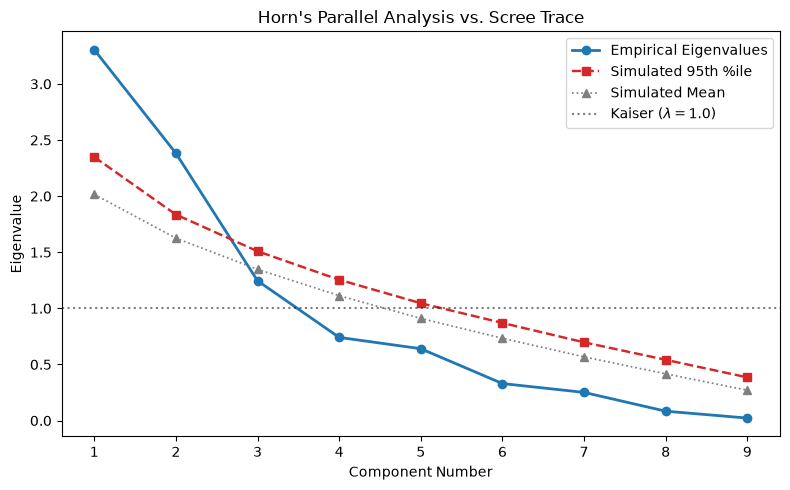

Horn's Parallel Analysis Eigenvalue Comparison:


,Empirical Eigenvalue,Synthetic (95th %ile),Synthetic (Mean),Retain
Component 1,3.304,2.349,2.016,Yes
Component 2,2.382,1.836,1.625,Yes
Component 3,1.246,1.509,1.348,No
Component 4,0.741,1.255,1.113,No
Component 5,0.640,1.046,0.910,No
Component 6,0.330,0.870,0.733,No
Component 7,0.251,0.697,0.568,No
Component 8,0.084,0.542,0.416,No
Component 9,0.022,0.385,0.270,No


Optimal Factors Suggested by Parallel Analysis: 2


In [32]:

# =========================================================================
# STEP 4: Retention Diagnostics (Parallel Analysis & Scree Plot)
# =========================================================================
print("\n" + "=" * 70)
print("STEP 4: FACTOR RETENTION (HORN'S PARALLEL ANALYSIS & KAISER)")
print("=" * 70)

parallel_results = perform_horn_parallel_analysis(
    df=df_metrics,
    corr_matrix=poly_corr,
    n_simulations=1000,
    percentile=95.0,
    random_state=random_state,
    plot_comparison=True,
)
pipeline_results["parallel_analysis"] = parallel_results

print("Horn's Parallel Analysis Eigenvalue Comparison:")
display(parallel_results["comparison_table"].round(3))
print(f"Optimal Factors Suggested by Parallel Analysis: {parallel_results['n_factors_parallel']}")


In [33]:

# =========================================================================
# STEP 5: PCA with Direct Oblimin Rotation (Abels et al. Model)
# =========================================================================
print("\n" + "=" * 70)
print("STEP 5: PCA WITH DIRECT OBLIMIN ROTATION")
print("=" * 70)

# Fits target PCA using factor_analyzer (uses parallel analysis factor count if desired, or defaults to Kaiser)
retained_factors = parallel_results["n_factors_parallel"] if parallel_results["n_factors_parallel"] > 0 else None

retained_factors = 3

pca_results = perform_abels_pca_oblimin(
    corr_matrix=poly_corr,
    n_factors=retained_factors,
    kaiser_cutoff=1.0,
    rotation="oblimin",
)
pipeline_results["pca"] = pca_results

print("Variance Explained Breakdown:")
display(pca_results["variance_summary"].round(2))

print("\nRotated Pattern Matrix (Table 3 Style):")
display(pca_results["pattern_loadings"].round(3))

print("\nStructure Matrix (Table 4 Style):")
display(pca_results["structure_matrix"].round(3))

print("\nComponent Correlations (Phi):")
display(pca_results["factor_correlations"].round(3))



STEP 5: PCA WITH DIRECT OBLIMIN ROTATION
Variance Explained Breakdown:


,Eigenvalue,% of Variance,Cumulative %
Component 1,3.30,36.71,36.71
Component 2,2.38,26.47,63.18
Component 3,1.25,13.84,77.02
Component 4,0.74,8.24,85.26
Component 5,0.64,7.11,92.37
Component 6,0.33,3.66,96.04
Component 7,0.25,2.79,98.82
Component 8,0.08,0.93,99.75
Component 9,0.02,0.25,100.00



Rotated Pattern Matrix (Table 3 Style):


,Component 1,Component 2,Component 3
Chain of Custody,-0.844,-0.177,0.058
Authenticity,-0.907,-0.063,-0.099
Integrity,-0.932,0.365,0.150
Reliability,-0.194,0.787,-0.036
Lawful Acquisition,-0.171,-0.116,-0.859
Fact vs Inference,0.330,0.419,-0.541
Competence and Qualification,0.085,0.317,-0.735
Repeatability and reproducibility,0.069,0.863,-0.054
Privacy compliance,-0.758,-0.181,-0.426



Structure Matrix (Table 4 Style):


,Component 1,Component 2,Component 3
Chain of Custody,-0.853,-0.257,-0.014
Authenticity,-0.924,-0.130,-0.191
Integrity,-0.884,0.267,0.004
Reliability,-0.130,0.774,-0.151
Lawful Acquisition,-0.275,-0.029,-0.864
Fact vs Inference,0.307,0.512,-0.554
Competence and Qualification,0.032,0.412,-0.763
Repeatability and reproducibility,0.138,0.876,-0.149
Privacy compliance,-0.820,-0.196,-0.488



Component Correlations (Phi):


,Component 1,Component 2,Component 3
Component 1,1.000,0.087,0.110
Component 2,0.087,1.000,-0.119
Component 3,0.110,-0.119,1.000


In [34]:
# =========================================================================
# STEP 6: Scale Internal Consistency & Reliability
# =========================================================================
print("\n" + "=" * 70)
print("STEP 6: ORDINAL SCALE RELIABILITY & COMPOSITE RELIABILITY")
print("=" * 70)

reliability = compute_ordinal_reliability(
    df=df_metrics,
    poly_corr_matrix=poly_corr,
    n_bootstraps=n_bootstraps,
    alpha_ci=0.05,
    random_state=random_state,
)
pipeline_results["reliability"] = reliability

print(f"Ordinal Cronbach's Alpha: {reliability['ordinal_cronbach_alpha']:.3f} | 95% CI: [{reliability['ordinal_alpha_ci_95'][0]:.3f}, {reliability['ordinal_alpha_ci_95'][1]:.3f}]")
print(f"McDonald's Omega (Composite): {reliability['composite_reliability_omega']:.3f} | 95% CI: [{reliability['omega_ci_95'][0]:.3f}, {reliability['omega_ci_95'][1]:.3f}]")
print(f"Standard Cronbach's Alpha: {reliability['standard_cronbach_alpha']:.3f} | 95% CI: [{reliability['standard_alpha_ci_95'][0]:.3f}, {reliability['standard_alpha_ci_95'][1]:.3f}]")
print("\nSingle-Factor CFA Standardized Loadings (Unidimensional Model):")
display(reliability["single_factor_loadings"].round(3))




STEP 6: ORDINAL SCALE RELIABILITY & COMPOSITE RELIABILITY
Ordinal Cronbach's Alpha: 0.710 | 95% CI: [0.490, 0.836]
McDonald's Omega (Composite): 0.694 | 95% CI: [0.101, 0.875]
Standard Cronbach's Alpha: 0.723 | 95% CI: [0.535, 0.856]

Single-Factor CFA Standardized Loadings (Unidimensional Model):


,Standardized_Loading (λ),Error_Variance (θ)
Chain of Custody,0.843,0.290
Authenticity,0.928,0.138
Integrity,0.822,0.325
Reliability,0.080,0.994
Lawful Acquisition,0.411,0.831
Fact vs Inference,-0.247,0.939
Competence and Qualification,0.060,0.996
Repeatability and reproducibility,-0.186,0.966
Privacy compliance,0.885,0.217



STEP 7: PRE-CLUSTERING TRIANGULATION (SILHOUETTE, GAP STATISTIC, WARD)


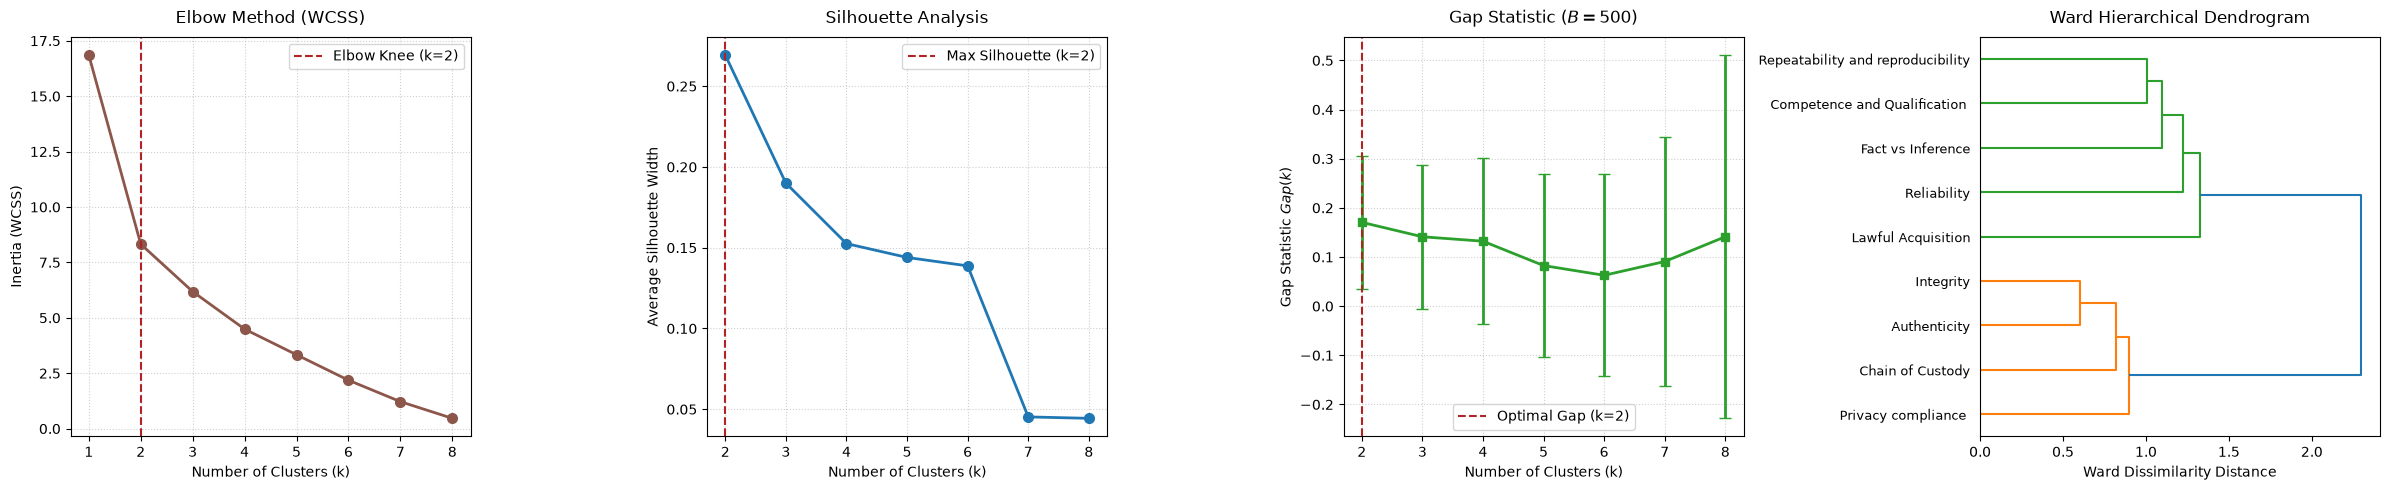

Triangulation Diagnostics Summary:


,Inertia (Elbow WCSS),Silhouette Score,Gap Statistic,Gap Std Error
k = 2,8.325,0.269,0.171,0.135
k = 3,6.185,0.190,0.141,0.147
k = 4,4.492,0.153,0.132,0.169
k = 5,3.334,0.144,0.083,0.187
k = 6,2.186,0.139,0.063,0.205
k = 7,1.219,0.045,0.091,0.254
k = 8,0.466,0.044,0.141,0.370


In [49]:

# =========================================================================
# STEP 7: Compute Pre-Clustering Triangulation
# =========================================================================
print("\n" + "=" * 70)
print("STEP 7: PRE-CLUSTERING TRIANGULATION (SILHOUETTE, GAP STATISTIC, WARD)")
print("=" * 70)

clustering_triangulation = compute_pre_clustering_triangulation(
    poly_corr_matrix=poly_corr,
    k_range=range(2, 10),
    n_bootstraps_gap=500,
    random_state=random_state,
    plot_results=True,
)
pipeline_results["clustering_triangulation"] = clustering_triangulation

print("Triangulation Diagnostics Summary:")
display(clustering_triangulation["triangulation_table"].round(3))


In [47]:
# =========================================================================
# STEP 7.5: Compute Pre-Clustering NBClust
# =========================================================================
print("\n" + "=" * 70)
print("STEP 7.5: PRE-CLUSTERING NBCLUST (MAJORITY VOTING)")
print("=" * 70)

clustering_nbclust = run_nbclust_via_rscript(
    data=df_metrics,
    min_nc=2,
    max_nc=10,
    method="kmeans",
    distance="euclidean",
    index="alllong",
)

pipeline_results["clustering_nbclust"] = clustering_nbclust

print(f"Optimal k Proposed by Majority Rule: k = {clustering_nbclust['optimal_k']}")

print("\nVote Tally Across Valid Indices:")
for k_val, count in sorted(clustering_nbclust["votes_per_k"].items()):
    print(f"  k = {k_val}: {count} votes")

print("\nIndex-by-Index Best Criterion Summary:")
display(clustering_nbclust["best_nc_summary"])

print("\nDetailed Internal Indices Table Across Tested k:")
display(clustering_nbclust["all_indices_table"].round(3))


STEP 7.5: PRE-CLUSTERING NBCLUST (MAJORITY VOTING)


Optimal k Proposed by Majority Rule: k = 6

Vote Tally Across Valid Indices:
  k = 2: 7 votes
  k = 3: 5 votes
  k = 4: 3 votes
  k = 6: 8 votes

Index-by-Index Best Criterion Summary:


,KL,CH,Hartigan,CCC,Scott,Marriot,TrCovW,TraceW,Friedman,Rubin,...,Frey,McClain,Gamma,Gplus,Tau,Dunn,Hubert,SDindex,Dindex,SDbw
Number_clusters,6.000,2.0000,6.0000,2.0000,4.0000,4.0000,3.0000,3.0000,6.0000,3.0000,...,1.0,2.0000,6.0000,6.000,-inf,0.3536,0,1.7317,0,0.3815
Value_Index,2.694,9.8123,3.2579,5.2035,87.8719,150132.7498,42.7368,5.2944,2072.3351,-0.0497,...,NaN,0.5631,0.8126,4.943,2.0,0.0000,6,0.0000,6,6.0000



Detailed Internal Indices Table Across Tested k:


,KL,CH,Hartigan,CCC,Scott,Marriot,TrCovW,TraceW,Friedman,Rubin,...,Frey,McClain,Gamma,Gplus,Tau,Dunn,Hubert,SDindex,Dindex,SDbw
2,1.335,9.812,7.001,5.204,148.546,392476.741,96.781,65.111,775.991,7.387,...,0.792,0.563,0.598,16.678,NaN,0.354,0.022,2.119,1.429,0.917
3,1.396,9.389,5.124,3.943,192.691,172160.070,54.044,50.867,638.271,9.456,...,0.604,1.174,0.626,13.946,NaN,0.250,0.029,2.242,1.266,0.821
4,1.057,8.916,4.810,3.768,280.563,11813.886,34.903,41.917,1133.674,11.475,...,-0.119,1.747,0.653,10.789,NaN,0.250,0.028,2.014,1.126,0.657
5,0.842,8.885,5.902,3.849,346.585,1600.453,24.634,34.667,1715.875,13.875,...,0.062,1.752,0.695,9.245,NaN,0.333,0.030,1.745,1.020,0.468
6,2.694,9.732,2.645,4.415,370.968,934.125,13.262,27.333,3788.210,17.598,...,1.392,1.953,0.813,4.943,NaN,0.316,0.034,1.732,0.915,0.382


In [54]:

# =========================================================================
# STEP 8: Project & Cluster Publications
# =========================================================================
print("\n" + "=" * 70)
print("STEP 8: PUBLICATION PROJECTION & CLUSTERING")
print("=" * 70)

optimal_k = clustering_triangulation["optimal_k_silhouette"]

pca_clusters = project_and_cluster_publications(
    df_metrics=df_metrics,
    pca_results=pipeline_results["pca"],
    n_clusters=2,
    clustering_method="kmeans",
    publication_labels=pub_labels,
    random_state=random_state,
    plot_scatter=True,
)
pipeline_results["publication_clusters"] = pca_clusters

print(f"Cluster Assignments (k={optimal_k}):")
display(pca_clusters["clustered_publications"])

print(f"\nMean Metric Profiles (0-2 Scale) Across Clusters:")
display(pca_clusters["cluster_metric_profiles"].round(2))


STEP 8: PUBLICATION PROJECTION & CLUSTERING


Cluster Assignments (k=2):


,Publication,Assigned_Cluster,PCA_Comp_1,PCA_Comp_2,PCA_Comp_3
Burri_2020,Burri_2020,Cluster_2,-0.262917,0.044107,1.244066
Balmiki_2023,Balmiki_2023,Cluster_2,-0.270378,-0.591692,1.176486
Akbarfam_2023,Akbarfam_2023,Cluster_1,-0.490382,-0.310470,-1.050707
Ahmad_2020,Ahmad_2020,Cluster_1,-0.753815,0.926436,1.060101
Lusetti_2020,Lusetti_2020,Cluster_1,-0.620117,-0.985049,0.074381
Li_2019,Li_2019,Cluster_1,-0.612656,-0.349250,0.141961
Li_2023,Li_2023,Cluster_1,-0.664083,-1.207140,-0.698015
Kumar_2021,Kumar_2021,Cluster_1,-0.664083,-1.207140,-0.698015
Jacob_2022,Jacob_2022,Cluster_1,-0.620117,-0.985049,0.074381
Harding_2024,Harding_2024,Cluster_1,0.063977,1.741233,0.036603



Mean Metric Profiles (0-2 Scale) Across Clusters:


,Chain of Custody,Authenticity,Integrity,Reliability,Lawful Acquisition,Fact vs Inference,Competence and Qualification,Repeatability and reproducibility,Privacy compliance
Assigned_Cluster,,,,,,,,,
Cluster_1,1.94,1.94,2.00,1.17,1.17,0.33,0.56,1.00,1.89
Cluster_2,1.22,1.22,1.56,1.00,0.22,0.33,0.00,0.89,0.56


In [55]:

# =========================================================================
# STEP 8: Project & Cluster Publications
# =========================================================================
print("\n" + "=" * 70)
print("STEP 8: PUBLICATION PROJECTION & CLUSTERING")
print("=" * 70)

optimal_k = clustering_triangulation["optimal_k_silhouette"]

pca_clusters = project_and_cluster_publications(
    df_metrics=df_metrics,
    pca_results=pipeline_results["pca"],
    n_clusters=2,
    clustering_method="hierarchical",
    publication_labels=pub_labels,
    random_state=random_state,
    plot_scatter=True,
    draw_hyperplanes=True,
    save_path=None
)
pipeline_results["publication_clusters"] = pca_clusters

print(f"Cluster Assignments (k={optimal_k}):")
display(pca_clusters["clustered_publications"])

print(f"\nMean Metric Profiles (0-2 Scale) Across Clusters:")
display(pca_clusters["cluster_metric_profiles"].round(2))


STEP 8: PUBLICATION PROJECTION & CLUSTERING


Cluster Assignments (k=2):


,Publication,Assigned_Cluster,PCA_Comp_1,PCA_Comp_2,PCA_Comp_3
Burri_2020,Burri_2020,Cluster_1,-0.262917,0.044107,1.244066
Balmiki_2023,Balmiki_2023,Cluster_1,-0.270378,-0.591692,1.176486
Akbarfam_2023,Akbarfam_2023,Cluster_2,-0.490382,-0.310470,-1.050707
Ahmad_2020,Ahmad_2020,Cluster_1,-0.753815,0.926436,1.060101
Lusetti_2020,Lusetti_2020,Cluster_2,-0.620117,-0.985049,0.074381
Li_2019,Li_2019,Cluster_2,-0.612656,-0.349250,0.141961
Li_2023,Li_2023,Cluster_2,-0.664083,-1.207140,-0.698015
Kumar_2021,Kumar_2021,Cluster_2,-0.664083,-1.207140,-0.698015
Jacob_2022,Jacob_2022,Cluster_2,-0.620117,-0.985049,0.074381
Harding_2024,Harding_2024,Cluster_1,0.063977,1.741233,0.036603



Mean Metric Profiles (0-2 Scale) Across Clusters:


,Chain of Custody,Authenticity,Integrity,Reliability,Lawful Acquisition,Fact vs Inference,Competence and Qualification,Repeatability and reproducibility,Privacy compliance
Assigned_Cluster,,,,,,,,,
Cluster_1,1.36,1.27,1.64,1.18,0.27,0.27,0.09,1.00,0.73
Cluster_2,1.94,2.00,2.00,1.06,1.25,0.38,0.56,0.94,1.94
